# 04 - Modelagem preditiva

## 1. Objetivo do notebook

Este notebook tem como objetivo preparar os dados e desenvolver os modelos preditivos para estimar a precipitação diária da estação A701.

A modelagem será construída a partir dos resultados obtidos na análise exploratória. Serão consideradas informações temporais da própria série, características sazonais e variáveis meteorológicas auxiliares.

Os modelos serão avaliados respeitando a ordem cronológica dos dados, evitando o uso de informações futuras durante o treinamento e permitindo uma comparação consistente entre diferentes estratégias de previsão.

## 2. Carregamento da base diária

A modelagem utiliza como ponto de partida a base diária consolidada na camada Gold, produzida após as etapas de controle de qualidade e pré-processamento.

Nesta etapa, a base é carregada e sua estrutura é verificada antes da criação das variáveis utilizadas pelos modelos.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

caminho_gold = Path("../data/gold/a701_2010_2025_diario_horario_sp.parquet")
assert caminho_gold.exists(), f"Arquivo Gold não encontrado: {caminho_gold}"
df = pd.read_parquet(caminho_gold)

df["DATA (YYYY-MM-DD)"] = pd.to_datetime(df["DATA (YYYY-MM-DD)"])
df = df.sort_values("DATA (YYYY-MM-DD)").reset_index(drop=True)
assert df["DATA (YYYY-MM-DD)"].is_unique, "Existem datas duplicadas na base Gold."
assert (df["DATA (YYYY-MM-DD)"].diff().dropna() == pd.Timedelta(days=1)).all(), (
    "Há lacunas no calendário diário: shift(1) deixaria de significar dia anterior."
)
print("Base carregada:", caminho_gold)
display(df.head())

Base carregada: ..\data\gold\a701_2010_2025_diario_horario_sp.parquet


,DATA (YYYY-MM-DD),horas_validas,precipitacao_diaria_mm,horas_registradas,horas_esperadas,dia_completo,temperatura_media,umidade_media,pressao_media,vento_medio,temperatura_media_horas_validas,umidade_media_horas_validas,pressao_media_horas_validas,vento_medio_horas_validas
0,2010-01-01,24,6.4,24,24,True,21.212500,87.333333,923.108333,2.141667,24,24,24,24
1,2010-01-02,24,36.4,24,24,True,22.279167,84.041667,925.154167,1.179167,24,24,24,24
2,2010-01-03,24,0.4,24,24,True,24.370833,77.666667,926.783333,1.550000,24,24,24,24
3,2010-01-04,24,13.4,24,24,True,24.200000,74.416667,926.600000,1.804167,24,24,24,24
4,2010-01-05,24,50.2,24,24,True,24.641667,73.916667,923.858333,1.933333,24,24,24,24


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   DATA (YYYY-MM-DD)                5844 non-null   datetime64[us]
 1   horas_validas                    5844 non-null   int64         
 2   precipitacao_diaria_mm           5652 non-null   float64       
 3   horas_registradas                5844 non-null   int64         
 4   horas_esperadas                  5844 non-null   int64         
 5   dia_completo                     5844 non-null   bool          
 6   temperatura_media                5798 non-null   float64       
 7   umidade_media                    5805 non-null   float64       
 8   pressao_media                    5805 non-null   float64       
 9   vento_medio                      5805 non-null   float64       
 10  temperatura_media_horas_validas  5844 non-null   int64         
 11  um

In [3]:
print("Quantidade de registros:", len(df))
print("Data inicial:", df["DATA (YYYY-MM-DD)"].min())
print("Data final:", df["DATA (YYYY-MM-DD)"].max())

Quantidade de registros: 5844
Data inicial: 2010-01-01 00:00:00
Data final: 2025-12-31 00:00:00


## 3. Engenharia de atributos

A engenharia de atributos transforma informações disponíveis na série histórica em variáveis que possam ser utilizadas pelos modelos preditivos.

As variáveis desta etapa serão definidas com base nos resultados da análise exploratória. Foram identificados comportamento sazonal ao longo do ano, dependência temporal de curto prazo na precipitação e associações entre a chuva e variáveis meteorológicas auxiliares.

Por esse motivo, serão avaliados três grupos principais de atributos:

- atributos temporais e sazonais;
- valores anteriores da precipitação (lags);
- variáveis meteorológicas auxiliares.

A construção dessas variáveis deverá respeitar a ordem temporal da série, evitando o uso de informações futuras na previsão.

### 3.1 Atributos temporais

In [4]:
df["mes"] = df["DATA (YYYY-MM-DD)"].dt.month
df["dia_ano"] = df["DATA (YYYY-MM-DD)"].dt.dayofyear

In [5]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "mes",
        "dia_ano"
    ]
].head(10)

,DATA (YYYY-MM-DD),mes,dia_ano
0,2010-01-01,1,1
1,2010-01-02,1,2
2,2010-01-03,1,3
3,2010-01-04,1,4
4,2010-01-05,1,5
5,2010-01-06,1,6
6,2010-01-07,1,7
7,2010-01-08,1,8
8,2010-01-09,1,9
9,2010-01-10,1,10


In [6]:
df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)

In [7]:
df["dia_ano_sin"] = np.sin(2 * np.pi * df["dia_ano"] / 365.25)
df["dia_ano_cos"] = np.cos(2 * np.pi * df["dia_ano"] / 365.25)

In [8]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "mes",
        "mes_sin",
        "mes_cos",
        "dia_ano",
        "dia_ano_sin",
        "dia_ano_cos"
    ]
].head()

,DATA (YYYY-MM-DD),mes,mes_sin,mes_cos,dia_ano,dia_ano_sin,dia_ano_cos
0,2010-01-01,1,0.5,0.866025,1,0.017202,0.999852
1,2010-01-02,1,0.5,0.866025,2,0.034398,0.999408
2,2010-01-03,1,0.5,0.866025,3,0.051584,0.998669
3,2010-01-04,1,0.5,0.866025,4,0.068755,0.997634
4,2010-01-05,1,0.5,0.866025,5,0.085906,0.996303


In [9]:
df["precipitacao_lag_1"] = df["precipitacao_diaria_mm"].shift(1)
df["precipitacao_lag_2"] = df["precipitacao_diaria_mm"].shift(2)
df["precipitacao_lag_3"] = df["precipitacao_diaria_mm"].shift(3)

In [10]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "precipitacao_diaria_mm",
        "precipitacao_lag_1",
        "precipitacao_lag_2",
        "precipitacao_lag_3"
    ]
].head(10)

,DATA (YYYY-MM-DD),precipitacao_diaria_mm,precipitacao_lag_1,precipitacao_lag_2,precipitacao_lag_3
0,2010-01-01,6.4,NaN,NaN,NaN
1,2010-01-02,36.4,6.4,NaN,NaN
2,2010-01-03,0.4,36.4,6.4,NaN
3,2010-01-04,13.4,0.4,36.4,6.4
4,2010-01-05,50.2,13.4,0.4,36.4
5,2010-01-06,8.0,50.2,13.4,0.4
6,2010-01-07,0.2,8.0,50.2,13.4
7,2010-01-08,30.2,0.2,8.0,50.2
8,2010-01-09,0.2,30.2,0.2,8.0
9,2010-01-10,0.6,0.2,30.2,0.2


In [11]:
df[
    [
        "precipitacao_lag_1",
        "precipitacao_lag_2",
        "precipitacao_lag_3"
    ]
].isna().sum()

precipitacao_lag_1    192
precipitacao_lag_2    193
precipitacao_lag_3    194
dtype: int64

### Ausências geradas pelas defasagens

Os valores ausentes permanecem como `NaN` e não são convertidos em zero. Os lags são calculados **antes** de remover linhas incompletas, preservando seu significado de dias civis consecutivos. A quantidade de ausências será apresentada nas células executadas acima, pois pode mudar após a correção para o horário local.

In [12]:
df["media_movel_3"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

df["media_movel_7"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

In [13]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "precipitacao_diaria_mm",
        "media_movel_3",
        "media_movel_7"
    ]
].head(12)

,DATA (YYYY-MM-DD),precipitacao_diaria_mm,media_movel_3,media_movel_7
0,2010-01-01,6.4,NaN,NaN
1,2010-01-02,36.4,NaN,NaN
2,2010-01-03,0.4,NaN,NaN
3,2010-01-04,13.4,14.400000,NaN
4,2010-01-05,50.2,16.733333,NaN
5,2010-01-06,8.0,21.333333,NaN
6,2010-01-07,0.2,23.866667,NaN
7,2010-01-08,30.2,19.466667,16.428571
8,2010-01-09,0.2,12.800000,19.828571
9,2010-01-10,0.6,10.200000,14.657143


In [14]:
df[
    [
        "media_movel_3",
        "media_movel_7"
    ]
].isna().sum()

media_movel_3    443
media_movel_7    815
dtype: int64

In [15]:
colunas_modelagem = [
    "precipitacao_diaria_mm",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7",
    "temperatura_media",
    "umidade_media",
    "pressao_media",
    "vento_medio"
]

linhas_completas = df[colunas_modelagem].dropna()

print("Total de dias da série:", len(df))
print("Dias completos para modelagem:", len(linhas_completas))
print("Dias excluídos por alguma ausência:", len(df) - len(linhas_completas))

Total de dias da série: 5844
Dias completos para modelagem: 4953
Dias excluídos por alguma ausência: 891


### Impacto das ausências nas variáveis de modelagem

A exigência de histórico de precipitação completo nas janelas de 3 e 7 dias e a disponibilidade das variáveis meteorológicas reduzem o número de exemplos utilizáveis. **A contagem efetiva deve ser consultada na saída da célula anterior**. Nenhum valor ausente será substituído por zero.

## 4. Definição do horizonte de previsão

Para cada data-alvo local, o objetivo é prever sua precipitação diária com informações dos dias civis **anteriores**. As variáveis meteorológicas e a precipitação são defasadas em um dia (ou mais); somente características de calendário da data-alvo entram sem defasagem.

**Hipótese operacional:** as medições do dia local anterior estão disponíveis quando a previsão para o dia-alvo é emitida. Para emissão à meia-noite, isso depende da latência da publicação dos dados INMET. Esta hipótese deve ser declarada no relatório; caso a previsão seja emitida antes do fechamento do dia anterior, as variáveis deverão receber defasagem adicional.

In [16]:
df["temperatura_lag_1"] = df["temperatura_media"].shift(1)
df["umidade_lag_1"] = df["umidade_media"].shift(1)
df["pressao_lag_1"] = df["pressao_media"].shift(1)
df["vento_lag_1"] = df["vento_medio"].shift(1)

In [17]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "precipitacao_diaria_mm",
        "temperatura_media",
        "temperatura_lag_1",
        "umidade_media",
        "umidade_lag_1"
    ]
].head(5)

,DATA (YYYY-MM-DD),precipitacao_diaria_mm,temperatura_media,temperatura_lag_1,umidade_media,umidade_lag_1
0,2010-01-01,6.4,21.212500,NaN,87.333333,NaN
1,2010-01-02,36.4,22.279167,21.212500,84.041667,87.333333
2,2010-01-03,0.4,24.370833,22.279167,77.666667,84.041667
3,2010-01-04,13.4,24.200000,24.370833,74.416667,77.666667
4,2010-01-05,50.2,24.641667,24.200000,73.916667,74.416667


### Defasagem das variáveis meteorológicas auxiliares

As variáveis meteorológicas auxiliares foram deslocadas em um dia para representar um cenário de previsão de curto prazo.

Dessa forma, para estimar a precipitação de uma determinada data, o modelo utiliza os valores de temperatura, umidade, pressão e vento observados no dia anterior, evitando o uso de informações contemporâneas ao alvo.

Esse procedimento reduz o risco de vazamento de informação e mantém o experimento compatível com uma previsão de um dia à frente.

## 5. Definição dos cenários de modelagem

A comparação dos modelos será realizada em cenários com diferentes níveis de informação disponível.

O primeiro cenário utilizará apenas atributos temporais e históricos da própria precipitação. O segundo acrescentará variáveis meteorológicas auxiliares observadas no dia anterior. Essa separação permitirá avaliar se a inclusão das variáveis meteorológicas contribui para reduzir o erro de previsão em relação ao uso apenas do histórico da série.

In [18]:
features_temporais = [
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7"
]

features_multivariadas = features_temporais + [
    "temperatura_lag_1",
    "umidade_lag_1",
    "pressao_lag_1",
    "vento_lag_1"
]

alvo = "precipitacao_diaria_mm"

In [19]:
df_temporal = df[[alvo] + features_temporais].dropna()

df_multivariado = df[[alvo] + features_multivariadas].dropna()

print("Cenário temporal:")
print("Registros disponíveis:", len(df_temporal))

print("\nCenário multivariado:")
print("Registros disponíveis:", len(df_multivariado))

Cenário temporal:
Registros disponíveis: 4960

Cenário multivariado:
Registros disponíveis: 4953


### Base comum para comparação dos cenários

Para comparar os algoritmos nas mesmas condições, os cenários temporal e multivariado utilizam a interseção das datas com todos os atributos necessários presentes. Os números e as datas efetivos são calculados abaixo, sem reaproveitar as contagens da versão UTC.

In [20]:
colunas_base_comum = ["DATA (YYYY-MM-DD)", alvo] + features_multivariadas
base_modelagem = df[colunas_base_comum].dropna().copy().reset_index(drop=True)
assert base_modelagem["DATA (YYYY-MM-DD)"].is_monotonic_increasing
print("Registros na base comum:", len(base_modelagem))
print("Data inicial:", base_modelagem["DATA (YYYY-MM-DD)"].min())
print("Data final:", base_modelagem["DATA (YYYY-MM-DD)"].max())

Registros na base comum: 4953
Data inicial: 2010-01-08 00:00:00
Data final: 2025-12-21 00:00:00


## 6. Divisão temporal dos dados

Os 80% primeiros **registros elegíveis**, em ordem cronológica, compõem o treinamento; os 20% finais são reservados ao teste. A validação temporal e a busca de hiperparâmetros utilizam exclusivamente o treinamento.

Como linhas com histórico incompleto são excluídas, os índices consecutivos da base de modelagem nem sempre correspondem a dias consecutivos. Entretanto, todos os atributos `shift` e `rolling` foram construídos sobre a série diária completa, antes do descarte dessas linhas.

In [21]:
indice_corte = int(len(base_modelagem) * 0.8)

treino = base_modelagem.iloc[:indice_corte].copy()
teste = base_modelagem.iloc[indice_corte:].copy()

print("Total:", len(base_modelagem))
print("Treino:", len(treino))
print("Teste:", len(teste))

print("\nPeríodo de treino:")
print(
    treino["DATA (YYYY-MM-DD)"].min(),
    "até",
    treino["DATA (YYYY-MM-DD)"].max()
)

print("\nPeríodo de teste:")
print(
    teste["DATA (YYYY-MM-DD)"].min(),
    "até",
    teste["DATA (YYYY-MM-DD)"].max()
)

Total: 4953
Treino: 3962
Teste: 991

Período de treino:
2010-01-08 00:00:00 até 2022-01-11 00:00:00

Período de teste:
2022-01-12 00:00:00 até 2025-12-21 00:00:00


In [22]:
target = "precipitacao_diaria_mm"

y_train = treino[target].copy()
y_test = teste[target].copy()

In [23]:
features_temporais = [
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7"
]

features_multivariadas = features_temporais + [
    "temperatura_lag_1",
    "umidade_lag_1",
    "pressao_lag_1",
    "vento_lag_1"
]

In [24]:
X_train_temporal = treino[features_temporais].copy()
X_test_temporal = teste[features_temporais].copy()

X_train_multivariado = treino[features_multivariadas].copy()
X_test_multivariado = teste[features_multivariadas].copy()

In [25]:
print("Temporal")
print("X_train:", X_train_temporal.shape)
print("X_test:", X_test_temporal.shape)

print("\nMultivariado")
print("X_train:", X_train_multivariado.shape)
print("X_test:", X_test_multivariado.shape)

print("\nTarget")
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Temporal
X_train: (3962, 9)
X_test: (991, 9)

Multivariado
X_train: (3962, 13)
X_test: (991, 13)

Target
y_train: (3962,)
y_test: (991,)


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

tscv = TimeSeriesSplit(n_splits=5)

print("Validação temporal: 5 folds dentro do conjunto de treinamento.")
print("Teste reservado:", len(teste), "registros (não utilizado para seleção).")

Validação temporal: 5 folds dentro do conjunto de treinamento.
Teste reservado: 991 registros (não utilizado para seleção).


### Baseline de persistência

O baseline prevê a precipitação do dia-alvo utilizando o acumulado do dia anterior (`precipitacao_lag_1`). Seus resultados serão avaliados **nos cinco folds temporais de treinamento** e calculados abaixo; não reutilizamos o desempenho observado anteriormente na versão UTC.

### Regressão linear — cenário temporal

A regressão linear será ajustada em cada fold temporal do conjunto de treinamento. O gráfico de dispersão apresentado na sequência serve para examinar padrões de erro; seus resultados efetivos dependem da nova base local.

In [27]:
predicoes_validacao_temporal = []
reais_validacao_temporal = []
indices_validacao_temporal = []
maes_linear_temporal, rmses_linear_temporal = [], []

for fold, (idx_train, idx_val) in enumerate(tscv.split(X_train_temporal), start=1):
    X_tr, X_val = X_train_temporal.iloc[idx_train], X_train_temporal.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_train], y_train.iloc[idx_val]
    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_val)
    predicoes_validacao_temporal.extend(y_pred)
    reais_validacao_temporal.extend(y_val.to_numpy())
    indices_validacao_temporal.extend(idx_val)
    maes_linear_temporal.append(mean_absolute_error(y_val, y_pred))
    rmses_linear_temporal.append(np.sqrt(mean_squared_error(y_val, y_pred)))
    print(f"Fold {fold} | MAE: {maes_linear_temporal[-1]:.3f} mm | RMSE: {rmses_linear_temporal[-1]:.3f} mm")

print(f"Médias | MAE: {np.mean(maes_linear_temporal):.3f} mm | RMSE: {np.mean(rmses_linear_temporal):.3f} mm")

Fold 1 | MAE: 5.825 mm | RMSE: 10.149 mm
Fold 2 | MAE: 6.349 mm | RMSE: 10.792 mm
Fold 3 | MAE: 5.711 mm | RMSE: 10.126 mm
Fold 4 | MAE: 5.874 mm | RMSE: 12.028 mm
Fold 5 | MAE: 4.850 mm | RMSE: 8.283 mm
Médias | MAE: 5.722 mm | RMSE: 10.275 mm


In [28]:
predicoes_validacao_temporal = np.array(
    predicoes_validacao_temporal
)

reais_validacao_temporal = np.array(
    reais_validacao_temporal
)

indices_validacao_temporal = np.array(
    indices_validacao_temporal
)

print("Valores reais:", len(reais_validacao_temporal))
print("Previsões:", len(predicoes_validacao_temporal))

Valores reais: 3300
Previsões: 3300


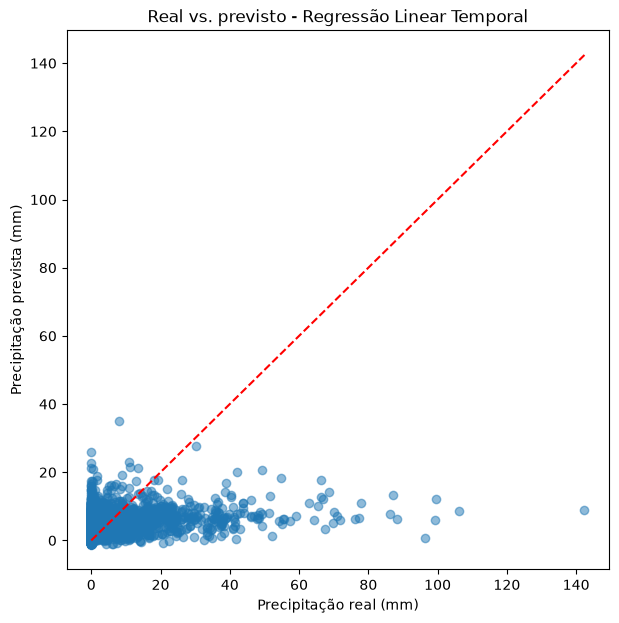

In [29]:
plt.figure(figsize=(7, 7))

plt.scatter(
    reais_validacao_temporal,
    predicoes_validacao_temporal,
    alpha=0.5
)

limite = max(
    reais_validacao_temporal.max(),
    predicoes_validacao_temporal.max()
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    color="red"
)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Temporal")

plt.show()

A dispersão permite investigar o viés de previsão, especialmente nos dias com precipitação elevada. Interprete o padrão após executar o gráfico nesta versão com datas locais, sem assumir que os erros são idênticos aos da versão UTC.

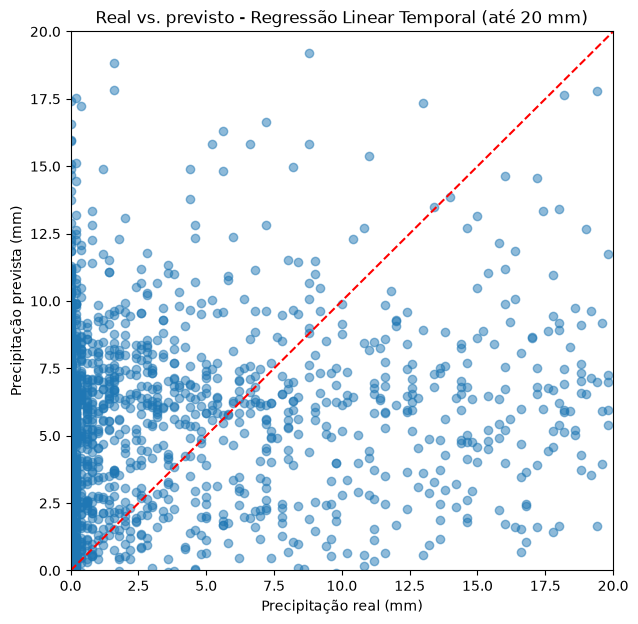

In [30]:
plt.figure(figsize=(7, 7))

mascara_zoom = reais_validacao_temporal <= 20

plt.scatter(
    reais_validacao_temporal[mascara_zoom],
    predicoes_validacao_temporal[mascara_zoom],
    alpha=0.5
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="red"
)

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Temporal (até 20 mm)")

plt.show()

In [31]:
predicoes_validacao_multi = []
reais_validacao_multi = []
maes_linear_multi, rmses_linear_multi = [], []

for fold, (idx_train, idx_val) in enumerate(tscv.split(X_train_multivariado), start=1):
    X_tr, X_val = X_train_multivariado.iloc[idx_train], X_train_multivariado.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_train], y_train.iloc[idx_val]
    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_val)
    predicoes_validacao_multi.extend(y_pred)
    reais_validacao_multi.extend(y_val.to_numpy())
    maes_linear_multi.append(mean_absolute_error(y_val, y_pred))
    rmses_linear_multi.append(np.sqrt(mean_squared_error(y_val, y_pred)))
    print(f"Fold {fold} | MAE: {maes_linear_multi[-1]:.3f} mm | RMSE: {rmses_linear_multi[-1]:.3f} mm")

predicoes_validacao_multi = np.array(predicoes_validacao_multi)
reais_validacao_multi = np.array(reais_validacao_multi)
print(f"Médias | MAE: {np.mean(maes_linear_multi):.3f} mm | RMSE: {np.mean(rmses_linear_multi):.3f} mm")

Fold 1 | MAE: 5.980 mm | RMSE: 10.068 mm
Fold 2 | MAE: 6.245 mm | RMSE: 10.658 mm
Fold 3 | MAE: 5.578 mm | RMSE: 10.058 mm
Fold 4 | MAE: 5.973 mm | RMSE: 11.948 mm
Fold 5 | MAE: 4.762 mm | RMSE: 8.130 mm
Médias | MAE: 5.708 mm | RMSE: 10.172 mm


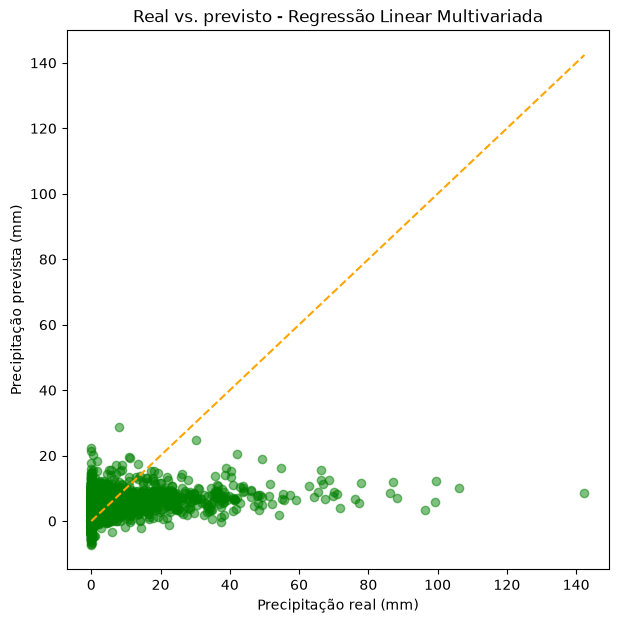

In [32]:
plt.figure(figsize=(7, 7))

plt.scatter(
    reais_validacao_multi,
    predicoes_validacao_multi,
    alpha=0.5,
    color="green"
)

limite = max(
    reais_validacao_multi.max(),
    predicoes_validacao_multi.max()
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    color="orange"
)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Multivariada")

plt.show()

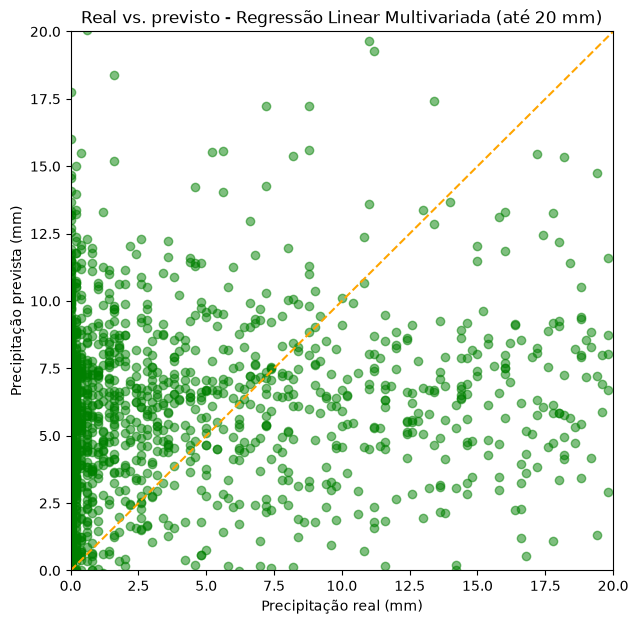

In [33]:
plt.figure(figsize=(7, 7))

mascara_zoom = reais_validacao_multi <= 20

plt.scatter(
    reais_validacao_multi[mascara_zoom],
    predicoes_validacao_multi[mascara_zoom],
    alpha=0.5,
    color="green"
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="orange"
)

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Multivariada (até 20 mm)")

plt.show()

Os gráficos com as previsões multivariadas permitem avaliar se a inclusão de variáveis meteorológicas do dia anterior altera o padrão de erros. A comparação quantitativa será apresentada na tabela calculada diretamente a partir das métricas por fold.

In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

In [35]:
maes_baseline = []
rmses_baseline = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_train_temporal),
    start=1
):

    y_val = y_train.iloc[idx_val]

    # Baseline de persistência:
    # previsão = precipitação do dia anterior
    y_pred_baseline = (
        X_train_temporal
        .iloc[idx_val]["precipitacao_lag_1"]
    )

    mae = mean_absolute_error(
        y_val,
        y_pred_baseline
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            y_pred_baseline
        )
    )

    maes_baseline.append(mae)
    rmses_baseline.append(rmse)

    print(
        f"Fold {fold} | "
        f"MAE: {mae:.3f} mm | "
        f"RMSE: {rmse:.3f} mm"
    )

print("\nMédia dos folds")
print(
    f"MAE médio: {np.mean(maes_baseline):.3f} mm"
)
print(
    f"RMSE médio: {np.mean(rmses_baseline):.3f} mm"
)

Fold 1 | MAE: 5.948 mm | RMSE: 12.838 mm
Fold 2 | MAE: 6.496 mm | RMSE: 13.196 mm
Fold 3 | MAE: 5.917 mm | RMSE: 13.269 mm
Fold 4 | MAE: 6.515 mm | RMSE: 15.928 mm
Fold 5 | MAE: 4.672 mm | RMSE: 10.830 mm

Média dos folds
MAE médio: 5.910 mm
RMSE médio: 13.212 mm


In [36]:
maes_rf_temporal = []
rmses_rf_temporal = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_train_temporal),
    start=1
):

    X_tr = X_train_temporal.iloc[idx_train]
    X_val = X_train_temporal.iloc[idx_val]

    y_tr = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    modelo_rf = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    modelo_rf.fit(X_tr, y_tr)

    y_pred = modelo_rf.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(
        mean_squared_error(y_val, y_pred)
    )

    maes_rf_temporal.append(mae)
    rmses_rf_temporal.append(rmse)

    print(
        f"Fold {fold} | "
        f"MAE: {mae:.3f} mm | "
        f"RMSE: {rmse:.3f} mm"
    )

print("\nMédia dos folds")
print(
    f"MAE médio: {np.mean(maes_rf_temporal):.3f} mm"
)
print(
    f"RMSE médio: {np.mean(rmses_rf_temporal):.3f} mm"
)

Fold 1 | MAE: 6.503 mm | RMSE: 10.903 mm
Fold 2 | MAE: 6.811 mm | RMSE: 11.217 mm
Fold 3 | MAE: 6.459 mm | RMSE: 11.173 mm
Fold 4 | MAE: 6.655 mm | RMSE: 12.777 mm
Fold 5 | MAE: 5.272 mm | RMSE: 8.712 mm

Média dos folds
MAE médio: 6.340 mm
RMSE médio: 10.956 mm


In [37]:
maes_rf_multi = []
rmses_rf_multi = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_train_multivariado),
    start=1
):

    X_tr = X_train_multivariado.iloc[idx_train]
    X_val = X_train_multivariado.iloc[idx_val]

    y_tr = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    modelo_rf = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    modelo_rf.fit(X_tr, y_tr)

    y_pred = modelo_rf.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    maes_rf_multi.append(mae)
    rmses_rf_multi.append(rmse)

    print(
        f"Fold {fold} | "
        f"MAE: {mae:.3f} mm | "
        f"RMSE: {rmse:.3f} mm"
    )

print("\nMédia dos folds")
print(f"MAE médio: {np.mean(maes_rf_multi):.3f} mm")
print(f"RMSE médio: {np.mean(rmses_rf_multi):.3f} mm")

Fold 1 | MAE: 6.210 mm | RMSE: 10.498 mm
Fold 2 | MAE: 6.332 mm | RMSE: 11.046 mm
Fold 3 | MAE: 5.753 mm | RMSE: 10.554 mm
Fold 4 | MAE: 6.195 mm | RMSE: 12.222 mm
Fold 5 | MAE: 5.167 mm | RMSE: 8.527 mm

Média dos folds
MAE médio: 5.931 mm
RMSE médio: 10.569 mm


### Comparação preliminar

A comparação entre Random Forest e regressão linear deve ser feita com os resultados recalculados nesta versão. As médias por fold estão disponíveis nas células anteriores; a tabela seguinte consolida esses resultados automaticamente.

In [38]:
resultados_modelos = pd.DataFrame({
    "Modelo": [
        "Baseline - Persistência",
        "Regressão Linear - Temporal",
        "Regressão Linear - Multivariada",
        "Random Forest - Temporal",
        "Random Forest - Multivariada"
    ],
    "MAE_medio_mm": [
        np.mean(maes_baseline), np.mean(maes_linear_temporal),
        np.mean(maes_linear_multi), np.mean(maes_rf_temporal),
        np.mean(maes_rf_multi)
    ],
    "RMSE_medio_mm": [
        np.mean(rmses_baseline), np.mean(rmses_linear_temporal),
        np.mean(rmses_linear_multi), np.mean(rmses_rf_temporal),
        np.mean(rmses_rf_multi)
    ]
})
display(resultados_modelos.round(3))

,Modelo,MAE_medio_mm,RMSE_medio_mm
0,Baseline - Persistência,5.910,13.212
1,Regressão Linear - Temporal,5.722,10.275
2,Regressão Linear - Multivariada,5.708,10.172
3,Random Forest - Temporal,6.340,10.956
4,Random Forest - Multivariada,5.931,10.569


In [39]:
mae_baseline = resultados_modelos.loc[
    resultados_modelos["Modelo"] == "Baseline - Persistência",
    "MAE_medio_mm"
].iloc[0]

rmse_baseline = resultados_modelos.loc[
    resultados_modelos["Modelo"] == "Baseline - Persistência",
    "RMSE_medio_mm"
].iloc[0]

In [40]:
resultados_modelos["Ganho_MAE_pct"] = (
    (mae_baseline - resultados_modelos["MAE_medio_mm"])
    / mae_baseline
) * 100

resultados_modelos["Ganho_RMSE_pct"] = (
    (rmse_baseline - resultados_modelos["RMSE_medio_mm"])
    / rmse_baseline
) * 100

In [41]:
resultados_modelos.round(2)

,Modelo,MAE_medio_mm,RMSE_medio_mm,Ganho_MAE_pct,Ganho_RMSE_pct
0,Baseline - Persistência,5.91,13.21,0.00,0.00
1,Regressão Linear - Temporal,5.72,10.28,3.18,22.23
2,Regressão Linear - Multivariada,5.71,10.17,3.42,23.01
3,Random Forest - Temporal,6.34,10.96,-7.28,17.07
4,Random Forest - Multivariada,5.93,10.57,-0.37,20.00


### Discussão das configurações iniciais

A tabela calculada acima resume a validação temporal no cenário local, com os mesmos registros elegíveis e as mesmas cinco divisões para todos os modelos. O ajuste de hiperparâmetros, a seguir, poderá alterar a ordem relativa de desempenho.

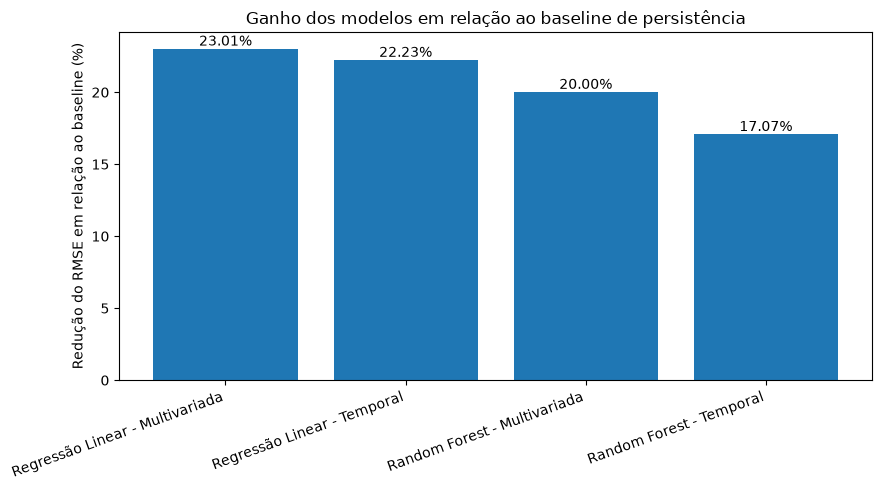

In [42]:
modelos_grafico = resultados_modelos[
    resultados_modelos["Modelo"] != "Baseline - Persistência"
].copy()

modelos_grafico = modelos_grafico.sort_values(
    "Ganho_RMSE_pct",
    ascending=False
)

plt.figure(figsize=(9, 5))

barras = plt.bar(
    modelos_grafico["Modelo"],
    modelos_grafico["Ganho_RMSE_pct"]
)

plt.ylabel("Redução do RMSE em relação ao baseline (%)")
plt.title("Ganho dos modelos em relação ao baseline de persistência")

plt.xticks(rotation=20, ha="right")

for barra, valor in zip(
    barras,
    modelos_grafico["Ganho_RMSE_pct"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{valor:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

O gráfico apresenta o ganho percentual de RMSE em relação ao baseline de persistência, calculado automaticamente com os resultados dos cinco folds na nova base local. Não se reutilizam percentuais da versão UTC.

### Ajuste de hiperparâmetros da Random Forest

Após a avaliação inicial dos modelos, foi realizado o ajuste dos hiperparâmetros da Random Forest no cenário multivariado.

A busca foi conduzida utilizando `RandomizedSearchCV`, combinada com o mesmo procedimento de validação temporal por `TimeSeriesSplit` utilizado nas comparações anteriores. Dessa forma, diferentes configurações do modelo foram avaliadas sem utilizar o conjunto de teste final.

Foram considerados parâmetros relacionados ao número e à profundidade das árvores, quantidade mínima de observações para divisão dos nós e folhas e quantidade de atributos avaliados em cada divisão.

O critério utilizado para seleção da melhor configuração foi o menor RMSE médio obtido na validação temporal.

In [43]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

parametros_rf = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", 0.5, 0.8, 1.0]
}

rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

busca_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=parametros_rf,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

busca_rf.fit(
    X_train_multivariado,
    y_train
)

print("Melhores parâmetros:")
print(busca_rf.best_params_)

print(
    "\nMelhor RMSE médio:",
    -busca_rf.best_score_
)

Melhores parâmetros:
{'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}

Melhor RMSE médio: 10.174948164803421


#### Configuração selecionada pela busca — Random Forest

Os hiperparâmetros e o RMSE da melhor combinação são impressos pela célula anterior. **Não presumimos que o melhor conjunto seja igual ao da base UTC**. A célula seguinte usa os parâmetros encontrados agora para calcular MAE e RMSE nos cinco folds.

In [44]:
melhores_parametros_rf = busca_rf.best_params_.copy()
print("Parâmetros de RF encontrados com os dados locais:")
print(melhores_parametros_rf)

Parâmetros de RF encontrados com os dados locais:
{'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}


In [45]:
maes_rf_otimizada = []
rmses_rf_otimizada = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_train_multivariado),
    start=1
):

    X_tr = X_train_multivariado.iloc[idx_train]
    X_val = X_train_multivariado.iloc[idx_val]

    y_tr = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    modelo_rf_otimizado = RandomForestRegressor(
        **melhores_parametros_rf,
        random_state=42,
        n_jobs=-1
    )

    modelo_rf_otimizado.fit(X_tr, y_tr)

    y_pred = modelo_rf_otimizado.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    maes_rf_otimizada.append(mae)
    rmses_rf_otimizada.append(rmse)

    print(
        f"Fold {fold} | "
        f"MAE: {mae:.3f} mm | "
        f"RMSE: {rmse:.3f} mm"
    )

print("\nMédia dos folds")
print(f"MAE médio: {np.mean(maes_rf_otimizada):.3f} mm")
print(f"RMSE médio: {np.mean(rmses_rf_otimizada):.3f} mm")

Fold 1 | MAE: 5.710 mm | RMSE: 10.100 mm
Fold 2 | MAE: 5.931 mm | RMSE: 10.711 mm
Fold 3 | MAE: 5.457 mm | RMSE: 10.126 mm
Fold 4 | MAE: 5.815 mm | RMSE: 11.858 mm
Fold 5 | MAE: 4.571 mm | RMSE: 8.079 mm

Média dos folds
MAE médio: 5.497 mm
RMSE médio: 10.175 mm


Os hiperparâmetros incluídos na busca foram selecionados por sua influência sobre a complexidade, regularização e diversidade das árvores da Random Forest. Foram avaliados diferentes números de estimadores, profundidades máximas, quantidades mínimas de observações para divisão e formação de folhas, além de diferentes proporções de atributos consideradas em cada divisão. Os intervalos foram definidos para explorar desde configurações mais flexíveis até mais restritivas, e a melhor combinação foi determinada pelo menor RMSE médio na validação temporal.

#### Avaliação da Random Forest otimizada

As médias de MAE e RMSE impressas acima correspondem à validação temporal com os parâmetros escolhidos pela busca na nova base local. Como a busca e esta avaliação usam os mesmos folds, os números refletem **avaliação orientada à seleção de hiperparâmetros**, não uma estimativa independente livre de viés de seleção.

### XGBoost

Como etapa adicional da comparação entre modelos, foi avaliado o algoritmo XGBoost no cenário multivariado.

O XGBoost é um método de boosting baseado em árvores de decisão construídas de forma sequencial, em que cada nova árvore busca corrigir parte dos erros cometidos pelas anteriores.

Para manter a comparabilidade com os modelos já avaliados, o desempenho foi estimado utilizando os mesmos cinco folds definidos pelo `TimeSeriesSplit`, considerando as métricas MAE e RMSE.

Nesta primeira avaliação foi utilizada uma configuração inicial do modelo, sem ajuste de hiperparâmetros.

In [46]:
from xgboost import XGBRegressor

maes_xgb = []
rmses_xgb = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_train_multivariado),
    start=1
):

    X_tr = X_train_multivariado.iloc[idx_train]
    X_val = X_train_multivariado.iloc[idx_val]

    y_tr = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    modelo_xgb = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    modelo_xgb.fit(X_tr, y_tr)

    y_pred = modelo_xgb.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    maes_xgb.append(mae)
    rmses_xgb.append(rmse)

    print(
        f"Fold {fold} | "
        f"MAE: {mae:.3f} mm | "
        f"RMSE: {rmse:.3f} mm"
    )

print("\nMédia dos folds")
print(f"MAE médio: {np.mean(maes_xgb):.3f} mm")
print(f"RMSE médio: {np.mean(rmses_xgb):.3f} mm")

Fold 1 | MAE: 6.581 mm | RMSE: 11.207 mm
Fold 2 | MAE: 6.598 mm | RMSE: 11.650 mm
Fold 3 | MAE: 6.249 mm | RMSE: 11.605 mm
Fold 4 | MAE: 6.251 mm | RMSE: 12.677 mm
Fold 5 | MAE: 5.461 mm | RMSE: 9.103 mm

Média dos folds
MAE médio: 6.228 mm
RMSE médio: 11.248 mm


### Ajuste de hiperparâmetros do XGBoost

Após a avaliação inicial do XGBoost, foi realizada uma etapa de ajuste de hiperparâmetros utilizando `RandomizedSearchCV` em conjunto com o mesmo procedimento de validação temporal por `TimeSeriesSplit`.

O objetivo foi avaliar diferentes combinações de parâmetros relacionados à complexidade das árvores, taxa de aprendizado e amostragem de observações e atributos, mantendo o conjunto de teste final preservado.

A seleção da melhor configuração foi baseada no menor RMSE médio obtido durante a validação temporal.

In [47]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

parametros_xgb = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [2, 3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 10]
}

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

busca_xgb = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=parametros_xgb,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

busca_xgb.fit(
    X_train_multivariado,
    y_train
)

print("Melhores parâmetros:")
print(busca_xgb.best_params_)

print(
    "\nMelhor RMSE médio:",
    -busca_xgb.best_score_
)

Melhores parâmetros:
{'subsample': 0.6, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.9}

Melhor RMSE médio: 10.161680365392838


#### Configuração selecionada pela busca — XGBoost

Os parâmetros e a pontuação da melhor combinação de XGBoost são apresentados pela célula anterior. Os valores da versão UTC não são reaproveitados. A validação temporal abaixo compara as métricas da configuração encontrada na base local.

In [48]:
melhores_parametros_xgb = busca_xgb.best_params_.copy()
maes_xgb_otimizado, rmses_xgb_otimizado = [], []

for fold, (idx_train, idx_val) in enumerate(tscv.split(X_train_multivariado), start=1):
    X_tr, X_val = X_train_multivariado.iloc[idx_train], X_train_multivariado.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_train], y_train.iloc[idx_val]
    modelo_xgb_otimizado = XGBRegressor(
        objective="reg:squarederror",
        **melhores_parametros_xgb,
        random_state=42, n_jobs=-1
    )
    modelo_xgb_otimizado.fit(X_tr, y_tr)
    y_pred = modelo_xgb_otimizado.predict(X_val)
    maes_xgb_otimizado.append(mean_absolute_error(y_val, y_pred))
    rmses_xgb_otimizado.append(np.sqrt(mean_squared_error(y_val, y_pred)))
    print(f"Fold {fold} | MAE: {maes_xgb_otimizado[-1]:.3f} mm | RMSE: {rmses_xgb_otimizado[-1]:.3f} mm")

print(f"Médias | MAE: {np.mean(maes_xgb_otimizado):.3f} mm | RMSE: {np.mean(rmses_xgb_otimizado):.3f} mm")

Fold 1 | MAE: 5.813 mm | RMSE: 10.022 mm
Fold 2 | MAE: 6.072 mm | RMSE: 10.712 mm
Fold 3 | MAE: 5.651 mm | RMSE: 10.099 mm
Fold 4 | MAE: 5.979 mm | RMSE: 11.909 mm
Fold 5 | MAE: 4.752 mm | RMSE: 8.038 mm
Médias | MAE: 5.653 mm | RMSE: 10.156 mm


#### Avaliação do XGBoost otimizado

As métricas do XGBoost são recalculadas nos cinco folds temporais sobre o treinamento da nova base local. Compare os resultados com a Random Forest ajustada, lembrando que ambos os processos de busca já utilizaram esses folds e que diferenças pequenas não demonstram superioridade estatística.

In [49]:
resultados_finais_validacao = pd.concat([
    resultados_modelos[["Modelo", "MAE_medio_mm", "RMSE_medio_mm"]],
    pd.DataFrame([
        {
            "Modelo": "Random Forest - Multivariada Otimizada",
            "MAE_medio_mm": np.mean(maes_rf_otimizada),
            "RMSE_medio_mm": np.mean(rmses_rf_otimizada)
        },
        {
            "Modelo": "XGBoost - Inicial",
            "MAE_medio_mm": np.mean(maes_xgb),
            "RMSE_medio_mm": np.mean(rmses_xgb)
        },
        {
            "Modelo": "XGBoost - Otimizado",
            "MAE_medio_mm": np.mean(maes_xgb_otimizado),
            "RMSE_medio_mm": np.mean(rmses_xgb_otimizado)
        }
    ])
], ignore_index=True).sort_values("RMSE_medio_mm").reset_index(drop=True)
display(resultados_finais_validacao.round(3))

,Modelo,MAE_medio_mm,RMSE_medio_mm
0,XGBoost - Otimizado,5.653,10.156
1,Regressão Linear - Multivariada,5.708,10.172
2,Random Forest - Multivariada Otimizada,5.497,10.175
3,Regressão Linear - Temporal,5.722,10.275
4,Random Forest - Multivariada,5.931,10.569
5,Random Forest - Temporal,6.340,10.956
6,XGBoost - Inicial,6.228,11.248
7,Baseline - Persistência,5.910,13.212


### Seleção do modelo para avaliação final

A tabela acima apresenta a comparação recalculada sobre os dias civis de São Paulo. A escolha do modelo final deve considerar **MAE, RMSE, complexidade e a finalidade de previsão de acumulados**, e ser explicitada após observar os resultados desta execução. O conjunto de teste não foi utilizado neste notebook para comparar ou ajustar os modelos.

O XGBoost - Otimizado apresentou o menor RMSE médio, com **10,156 mm**, enquanto a Random Forest otimizada apresentou RMSE médio de **10,569 mm**. A diferença entre os dois modelos foi, portanto, muito pequena.

Por outro lado, a Random Forest apresentou menor MAE médio, com **5,505 mm**, contra **5,668 mm** do XGBoost.

Considerando conjuntamente as duas métricas e a ausência de diferença relevante no RMSE, a **Random Forest multivariada otimizada** foi selecionada como modelo principal para a avaliação final no conjunto de teste.

O conjunto de teste permaneceu preservado durante todo o processo de comparação, seleção e ajuste de hiperparâmetros.